# 05 — Transfer Learning (estudo, treino) e Grad-CAM

**Data Challenge | Desafio 1: Classificação de doenças em folhas**

Continuação dos notebooks 01–04. Esta etapa cobre o estudo de arquitetura, o treino do MobileNetV2 (Entrega 2) e o Grad-CAM:

1. **Estudo de arquitetura (Parte A).** Comparar MobileNetV2, EfficientNetB0 e ResNet50 e justificar a escolha.
2. **Grad-CAM no baseline (Parte B).** Verificar no `baseline_aug` se o modelo olha para a folha/lesões ou para o fundo (hipótese da EDA, notebook 02).
3. **Treino MobileNetV2 (Parte C — Entrega 2).** Feature extraction → fine-tuning, métricas oficiais vs baseline, Grad-CAM no modelo final e discussão de deploy.


## 1. Continuação dos notebooks anteriores

Esta etapa precisa de dois insumos: os **dados** (`dataset`, `labels`, `test_ds`, do pipeline da etapa 1) e o **modelo baseline + augmentation** treinado no notebook 03.

A célula abaixo resolve os dois da forma mais barata possível:

- Se o notebook 03 já rodou **nesta sessão** (variável `runs` disponível), reaproveita tudo — modelos e dados — sem reexecutar nada.
- Senão, executa apenas o **notebook 01** com `%run` (ingestão e pré-processamento, rápido, **sem treino**) para obter os dados, e carrega o modelo salvo `data/processed/baseline_aug.keras` (produzido na seção 8 do notebook 03).
- Só se o modelo salvo não existir é que recorremos a `%run` do 03 (que treina as CNNs do zero, ~20–30 min em CPU).

Assim o notebook roda em segundos quando o 03 já foi executado, e continua funcionando do zero. A verificação vale por sessão do kernel: se alterar um notebook anterior, reinicie o kernel.

In [1]:
from pathlib import Path

from IPython import get_ipython
from IPython.utils.capture import capture_output

notebook_dir = Path.cwd()
if (notebook_dir / 'notebooks').is_dir():
    notebook_dir = notebook_dir / 'notebooks'
project_root = notebook_dir.parent
artifacts_dir = project_root / 'data' / 'processed'
baseline_aug_path = artifacts_dir / 'baseline_aug.keras'

# baseline_aug reaproveitado da sessão, carregado do disco, ou treinado (último caso).
gradcam_model = None

if 'runs' in globals() and 'baseline_aug' in globals().get('runs', {}):
    # (a) Notebook 03 já rodou nesta sessão: reaproveita modelos e dados.
    source = 'sessão (runs do notebook 03)'
    gradcam_model = runs['baseline_aug']['model']
elif baseline_aug_path.is_file():
    # (b) Modelo salvo existe: roda só o 01 (dados, sem treino) e carrega o modelo.
    source = 'data/processed/baseline_aug.keras (+ dados do notebook 01)'
    with capture_output():
        get_ipython().run_line_magic('run', f'"{notebook_dir / "01_data_ingestion_preprocessing.ipynb"}"')
else:
    # (c) Sem modelo salvo: executa o 03 (treina as CNNs do zero).
    source = '%run do notebook 03 (treino completo)'
    with capture_output():
        get_ipython().run_line_magic('run', f'"{notebook_dir / "03_baseline_model.ipynb"}"')
    gradcam_model = runs['baseline_aug']['model']

# Dados necessários à etapa 5 (vêm do 01 em qualquer caminho acima).
required = ['SEED', 'set_global_seed', 'IMAGE_SIZE', 'labels', 'dataset',
            'train_ds', 'train_aug_ds', 'val_ds', 'test_ds',
            'pd', 'plt', 'sns', 'np']
missing = [name for name in required if name not in globals()]
assert not missing, f'Variáveis indisponíveis: {missing}. Reinicie o kernel e rode de novo.'

FIGURES_DIR = project_root / 'reports' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print('fonte do baseline + augmentation:', source)
print('classes:', labels)
print('imagens de teste:', len(dataset['test']))


fonte do baseline + augmentation: data/processed/baseline_aug.keras (+ dados do notebook 01)
classes: ['angular_leaf_spot', 'bean_rust', 'healthy']
imagens de teste: 128


## 2. Setup específico da etapa 5

Importamos os helpers do pacote: catálogo `BACKBONES`, `build_transfer_model` / fine-tune e as funções de Grad-CAM. Fixamos a semente para seleção de exemplos e treino reprodutíveis.


In [2]:
import json
import time

from IPython.display import display
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from tensorflow import keras

from bean_leaf_disease.evaluation import (
    find_last_conv_layer,
    make_gradcam_heatmap,
    overlay_heatmap,
)
from bean_leaf_disease.models import (
    BACKBONES,
    build_transfer_model,
    count_trainable_weights,
    enable_finetune,
    get_backbone,
)

set_global_seed(SEED, deterministic=True)
ARTIFACTS_DIR = project_root / 'data' / 'processed'
print('figuras em:', FIGURES_DIR)
print('artefatos em:', ARTIFACTS_DIR)


figuras em: D:\dev\bean-leaf-disease-challenge\reports\figures
artefatos em: D:\dev\bean-leaf-disease-challenge\data\processed


## 3. Parte A — Estudo de arquiteturas de Transfer Learning

O baseline do notebook 03 é uma CNN pequena (23.779 parâmetros) treinada do zero, com cerca de 80–81% de acurácia no teste (notebook 04). O conjunto de treino tem apenas **1034 imagens**, e a EDA (notebook 02) mostrou que as lesões ocupam uma área pequena da folha e que o fundo (solo, mão) varia muito. Nesse cenário, treinar do zero uma rede grande tende a sofrer overfitting.

**Transfer Learning** contorna isso: usamos um backbone pré-treinado em ImageNet (1,2 milhão de imagens, 1000 classes) como **extrator de características**. As camadas convolucionais já aprenderam bordas, texturas e padrões que se transferem bem para folhas, e só treinamos um classificador leve no topo. É a abordagem padrão para datasets pequenos.

Comparamos três candidatas comuns, todas com entrada 224×224 (a mesma do pipeline da etapa 1).


In [3]:
tabela = pd.DataFrame(BACKBONES).T
tabela = tabela[['params_millions', 'size_mb', 'imagenet_top1', 'expects', 'note']]
tabela = tabela.rename(
    columns={
        'params_millions': 'parâmetros (M)',
        'size_mb': 'tamanho (MB)',
        'imagenet_top1': 'top-1 ImageNet',
        'expects': 'entrada esperada',
        'note': 'leitura para viabilidade',
    }
)
tabela['top-1 ImageNet'] = (tabela['top-1 ImageNet'].astype(float) * 100).round(1).astype(str) + '%'
with pd.option_context('display.max_colwidth', None):
    display(tabela)

,parâmetros (M),tamanho (MB),top-1 ImageNet,entrada esperada,leitura para viabilidade
MobileNetV2,3.5,14,71.3%,"[-1, 1]","Menor footprint. Projetado para dispositivos móveis/embarcados, adequado a inferência em campo. Treino rápido e menor risco de overfitting num dataset pequeno."
EfficientNetB0,5.3,29,77.1%,"[0, 255]","Melhor acurácia ImageNet entre as candidatas, ainda compacto. A normalização é interna ao modelo (espera pixels em [0, 255])."
ResNet50,25.6,98,74.9%,"caffe (BGR, centrado)",Arquitetura robusta e muito usada como referência. Maior e mais custosa; serve de teto de capacidade na comparação.


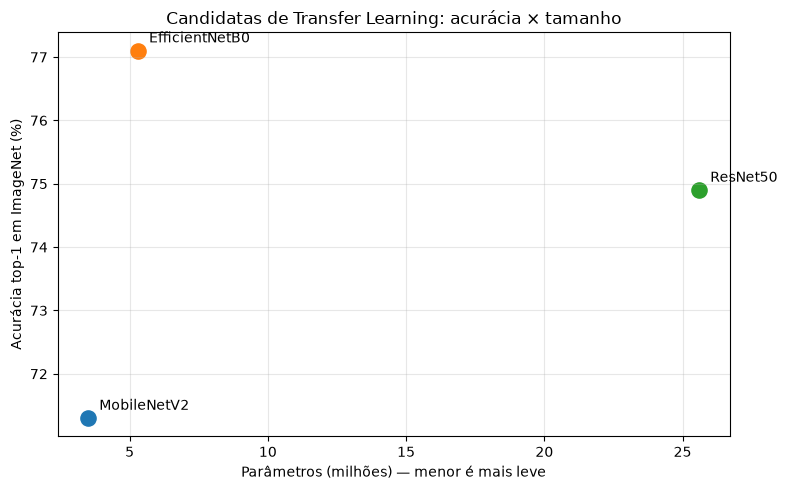

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, spec in BACKBONES.items():
    ax.scatter(spec['params_millions'], spec['imagenet_top1'] * 100, s=120)
    ax.annotate(
        name,
        (spec['params_millions'], spec['imagenet_top1'] * 100),
        textcoords='offset points', xytext=(8, 6),
    )
ax.set_xlabel('Parâmetros (milhões) — menor é mais leve')
ax.set_ylabel('Acurácia top-1 em ImageNet (%)')
ax.set_title('Candidatas de Transfer Learning: acurácia × tamanho')
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'tl_arquiteturas.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.1 Justificativa da escolha

As três candidatas superam com folga o baseline treinado do zero em ImageNet, mas a escolha para a Entrega 2 pesa **acurácia, custo e viabilidade operacional** (deploy em campo ou na agroindústria, tema pedido no enunciado da Entrega 2):

- **MobileNetV2 — escolha recomendada.** Menor footprint (3,5M parâmetros, 14 MB), projetado para dispositivos móveis/embarcados. É o mais adequado a inferência em campo (celular, borda) e o de menor risco de overfitting nas 1034 imagens de treino. Treina de forma viável em CPU com feature extraction + fine-tuning (Parte C).
- **EfficientNetB0 — alternativa de maior acurácia.** Melhor top-1 ImageNet (77,1%) ainda com tamanho moderado (5,3M, 29 MB). Fica como plano B se o MobileNetV2 não separar bem `bean_rust` de `angular_leaf_spot` (a confusão observada no notebook 04). Atenção: sua normalização é interna (espera pixels em [0, 255]).
- **ResNet50 — referência de capacidade.** Robusta e muito usada, mas grande (25,6M, 98 MB) e mais custosa, sem ganho claro de acurácia sobre a EfficientNetB0 aqui. Serve de teto de capacidade na comparação, não de candidata para deploy leve.

**Decisão:** **MobileNetV2** como extrator de características, com fine-tuning das camadas superiores na Parte C. A EfficientNetB0 permanece como plano B se a confusão `bean_rust` ↔ `angular_leaf_spot` não melhorar o suficiente.


### 3.2 Preview do pipeline (antes do treino)

`build_transfer_model` monta o modelo escolhido com o **mesmo topo do baseline** (GlobalAveragePooling2D → Dropout(0.3) → Dense softmax), para a comparação baseline × transfer learning ser justa. O pipeline da etapa 1 entrega pixels em [0, 1]; o construtor insere `Rescaling(255.0)` + o `preprocess_input` do backbone.

A célula abaixo só mostra a estrutura e a proporção de parâmetros congelados. O **treino de fato** (feature extraction + fine-tuning) está na Parte C.


In [5]:
preview_model = build_transfer_model('MobileNetV2', num_classes=len(labels), image_size=IMAGE_SIZE)

trainable, non_trainable = count_trainable_weights(preview_model)
print(f'Parâmetros treináveis (topo):   {trainable:,}')
print(f'Parâmetros congelados (backbone): {non_trainable:,}')
print(
    'Observe: com o backbone congelado, só o classificador do topo é treinado — '
    'poucos milhares de parâmetros, viável com 1034 imagens.'
)


Parâmetros treináveis (topo):   3,843
Parâmetros congelados (backbone): 2,257,984
Observe: com o backbone congelado, só o classificador do topo é treinado — poucos milhares de parâmetros, viável com 1034 imagens.


## 4. Parte B — Grad-CAM sobre o baseline + augmentation

O Grad-CAM destaca as regiões que mais pesaram na predição de uma classe. Aplicamos sobre o modelo **baseline + augmentation** do notebook 03 (o escolhido lá pela regra de seleção por validação) para responder: **o modelo olha para a folha ou para o fundo?**

Usamos a última **Conv2D** do baseline como alvo (`find_last_conv_layer` prioriza convolução, não o MaxPooling seguinte; mapa ~56×56×64).

In [6]:
# No caso (b) — modelo salvo em disco — ainda precisamos carregá-lo aqui.
if gradcam_model is None:
    gradcam_model = keras.models.load_model(baseline_aug_path)

last_conv = find_last_conv_layer(gradcam_model)
print('modelo Grad-CAM pronto | última camada convolucional (alvo):', last_conv)

modelo Grad-CAM pronto | última camada convolucional (alvo): conv2d_8


### 4.1 Seleção de exemplos

Escolhemos exemplos do conjunto de **teste** (não usado no treino): um acerto de cada classe e, para contraste, um **erro** — priorizando a confusão `bean_rust` ↔ `angular_leaf_spot` observada na matriz de confusão do notebook 04. Cada imagem é pré-processada do mesmo jeito que no treino (224×224, pixels em [0, 1]).


In [7]:
import tensorflow as tf

# Reconstrói as imagens de teste na ordem original, pré-processadas (224x224, [0,1]).
test_images = []
test_labels = []
for images, lbls in test_ds:
    test_images.append(images.numpy())
    test_labels.append(lbls.numpy())
test_images = np.concatenate(test_images)
test_labels = np.concatenate(test_labels)

# Predições do baseline_aug sobre o teste.
probs = gradcam_model.predict(test_images, verbose=0)
preds = probs.argmax(axis=1)

# Um acerto por classe + um erro (de preferência bean_rust <-> angular_leaf_spot).
selected = []
for class_id in range(len(labels)):
    hits = np.flatnonzero((test_labels == class_id) & (preds == class_id))
    if len(hits):
        selected.append(('acerto', int(hits[0])))

errors = np.flatnonzero(test_labels != preds)
if len(errors):
    pair = {labels.index('bean_rust'), labels.index('angular_leaf_spot')}
    priority = [i for i in errors if test_labels[i] in pair and preds[i] in pair]
    selected.append(('erro', int(priority[0] if priority else errors[0])))

for tag, idx in selected:
    print(f'{tag}: real={labels[test_labels[idx]]}, previsto={labels[preds[idx]]} (idx {idx})')

acerto: real=angular_leaf_spot, previsto=angular_leaf_spot (idx 0)
acerto: real=bean_rust, previsto=bean_rust (idx 43)
acerto: real=healthy, previsto=healthy (idx 86)
erro: real=angular_leaf_spot, previsto=bean_rust (idx 13)


### 4.2 Mapas de calor

Para cada exemplo: imagem original, mapa de calor sobreposto e o rótulo real/previsto. Vermelho = região que mais pesou na predição.

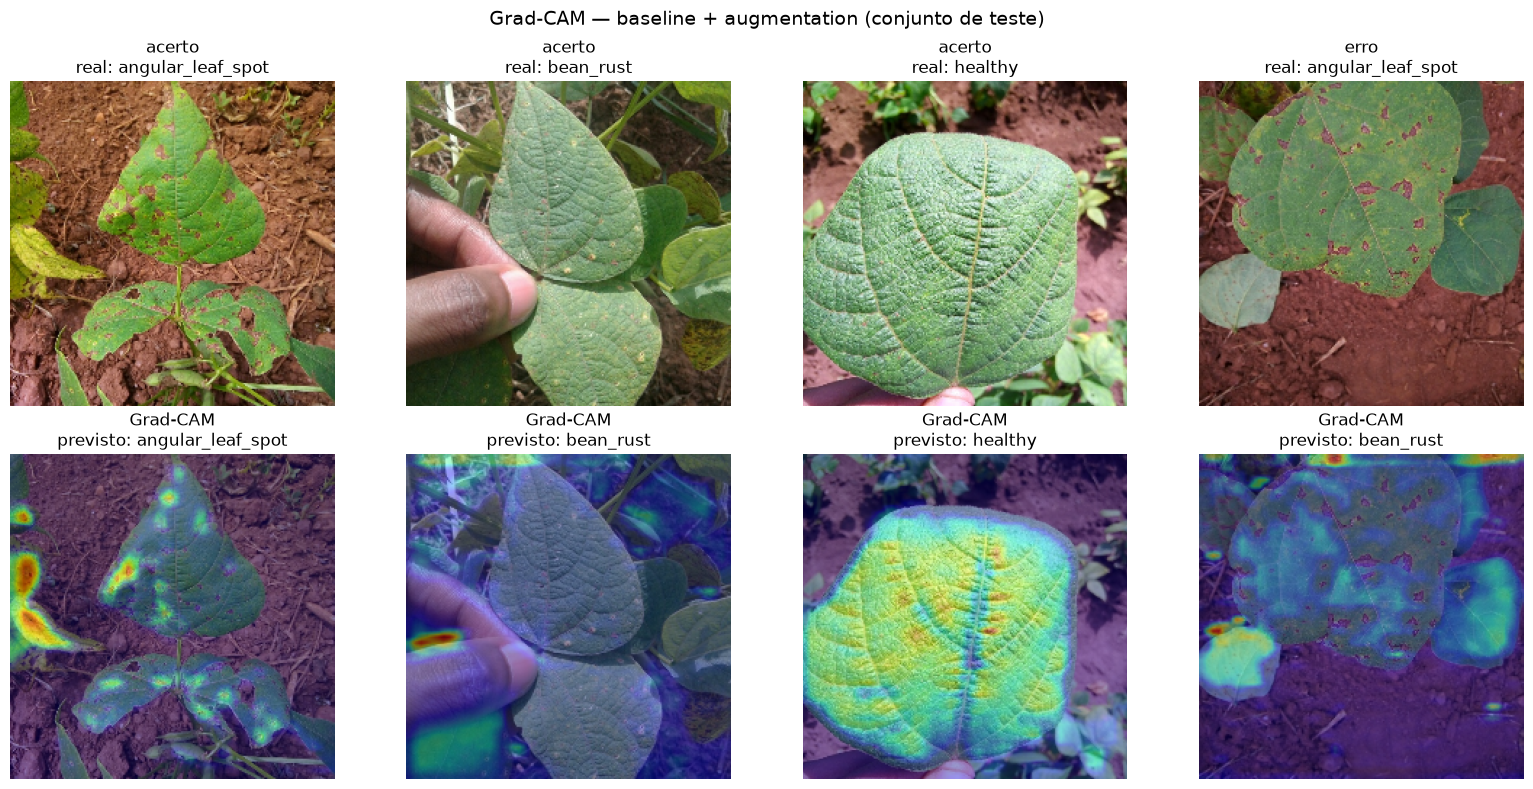

In [8]:
n = len(selected)
fig, axes = plt.subplots(2, n, figsize=(4 * n, 8))
axes = np.atleast_2d(axes)

for col, (tag, idx) in enumerate(selected):
    image = test_images[idx]
    img_batch = image[np.newaxis, ...]
    heatmap = make_gradcam_heatmap(img_batch, gradcam_model, last_conv, pred_index=int(preds[idx]))
    overlaid = overlay_heatmap(image, heatmap)

    real, previsto = labels[test_labels[idx]], labels[preds[idx]]
    axes[0, col].imshow(image)
    axes[0, col].set_title(f'{tag}\nreal: {real}')
    axes[1, col].imshow(overlaid)
    axes[1, col].set_title(f'Grad-CAM\nprevisto: {previsto}')
    for ax in axes[:, col]:
        ax.axis('off')

fig.suptitle('Grad-CAM — baseline + augmentation (conjunto de teste)', fontsize=14)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'gradcam_baseline.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.3 Leitura dos resultados

Nos quatro exemplos do teste (idxs 0, 43, 86 e 13), o Grad-CAM sobre `baseline_aug` mostra um quadro misto — em parte confirma a hipótese da EDA, em parte mostra aprendizado útil:

- **Acerto `angular_leaf_spot` (idx 0).** O vermelho/amarelo cai sobre a lâmina e coincide com lesões/furos da folha; o solo ao fundo fica frio. Aqui o modelo usa o sinal clínico esperado.
- **Acerto `bean_rust` (idx 43).** Há mão segurando a folha, e o hotspot principal concentra-se na **mão/polegar**, não nas pústulas. É o atalho de fundo/objeto que a EDA (notebook 02, seções 4 e 7) alertava: a predição pode estar certa pelo motivo errado.
- **Acerto `healthy` (idx 86).** A ativação cobre a superfície da folha (nervuras/lâmina) e pouco o solo — coerente com “folha sem padrão de doença”.
- **Erro `angular_leaf_spot` → `bean_rust` (idx 13).** O mapa ainda foca a folha e as manchas, não o chão; a falha parece ser de **discriminação entre sintomas parecidos**, não de atalho de fundo. Isso alinha com a matriz do notebook 04, onde a troca entre essas duas classes é a principal.

**Resolução.** O mapa vem da última Conv2D (~56×56), então indica regiões, não lesões milimétricas. Na Parte C, o Grad-CAM sobre MobileNetV2 (feature maps mais profundos) localiza melhor e permite checar se o Transfer Learning reduz a dependência de mão/fundo.

> Síntese: o baseline + augmentation às vezes olha para a folha (bons casos e o erro entre doenças), mas ainda pode ancorar em mão/contexto — motivação direta para Transfer Learning e para discutir confiabilidade em campo.


## 5. Parte C — Treino MobileNetV2 (Entrega 2)

Com a arquitetura escolhida na Parte A e o diagnóstico Grad-CAM da Parte B, treinamos o MobileNetV2 e comparamos com o baseline oficial (notebook 04).

Mesmo protocolo do notebook 03: teto de 200 épocas, early stopping com paciência 10, Adam. Usamos **augmentation** no treino (melhor validação no baseline e alinhado à EDA). Fine-tuning libera as últimas 40 camadas do MobileNetV2 com LR 1e-5. Depende das métricas oficiais do notebook 04 (`baseline_official_metrics.json`).


In [9]:
BACKBONE = 'MobileNetV2'
EPOCHS = 200
PATIENCE = 10
LR_HEAD = 1e-3
LR_FINETUNE = 1e-5
UNFREEZE_LAST = 40

baseline_official_path = ARTIFACTS_DIR / 'baseline_official_metrics.json'
assert baseline_official_path.exists(), (
    'Execute o notebook 04 antes para gerar baseline_official_metrics.json.'
)
baseline_official = json.loads(baseline_official_path.read_text(encoding='utf-8'))

print('Baseline (teste) já registrado:')
for key, row in baseline_official['results'].items():
    print(f"  {key}: acc={row['accuracy']:.4f} | f1_macro={row['f1_macro']:.4f}")


Baseline (teste) já registrado:
  baseline: acc=0.8125 | f1_macro=0.8093
  baseline_aug: acc=0.8047 | f1_macro=0.8055


### 5.1 Fase 1 — Feature extraction (backbone congelado)

Montamos o MobileNetV2 com `trainable_base=False`: só o topo (GAP → Dropout → Dense) é treinado. O pré-processamento ImageNet fica dentro do modelo (`Rescaling(255)` + `preprocess_input`), compatível com pixels `[0, 1]` do notebook 01.


In [10]:
set_global_seed(SEED, deterministic=True)
tl_model = build_transfer_model(
    BACKBONE,
    num_classes=len(labels),
    image_size=IMAGE_SIZE,
    trainable_base=False,
)
tl_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR_HEAD),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'],
)

trainable_n, frozen_n = count_trainable_weights(tl_model)
print(f'Backbone: {get_backbone(tl_model).name}')
print(f'Parâmetros treináveis (topo):   {trainable_n:,}')
print(f'Parâmetros congelados:          {frozen_n:,}')
tl_model.summary()

Backbone: mobilenetv2_1.00_224
Parâmetros treináveis (topo):   3,843
Parâmetros congelados:          2,257,984


Model: "transfer_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [11]:
early_stopping_fe = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=PATIENCE,
    restore_best_weights=True,
)

start_fe = time.perf_counter()
history_fe = tl_model.fit(
    train_aug_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping_fe],
    shuffle=False,
    verbose=2,
)
fe_time_s = time.perf_counter() - start_fe

history_fe_df = pd.DataFrame(history_fe.history)
history_fe_df.insert(0, 'epoch', range(1, len(history_fe_df) + 1))
history_fe_df['phase'] = 'feature_extraction'
best_fe_epoch = int(history_fe_df.loc[history_fe_df['val_loss'].idxmin(), 'epoch'])
stopped_fe = 'early stopping' if early_stopping_fe.stopped_epoch > 0 else 'teto de épocas'

print(
    f'Feature extraction: {len(history_fe_df)} épocas, melhor época {best_fe_epoch}, '
    f'parou por {stopped_fe}, {fe_time_s:.1f} s'
)
print(
    f"Melhor val_loss={history_fe_df.loc[history_fe_df['epoch'] == best_fe_epoch, 'val_loss'].iloc[0]:.4f} | "
    f"val_acc={history_fe_df.loc[history_fe_df['epoch'] == best_fe_epoch, 'val_accuracy'].iloc[0]:.4f}"
)

Epoch 1/200


33/33 - 33s - 1s/step - accuracy: 0.6132 - loss: 0.8386 - val_accuracy: 0.8271 - val_loss: 0.4856


Epoch 2/200


33/33 - 28s - 840ms/step - accuracy: 0.7901 - loss: 0.5185 - val_accuracy: 0.8421 - val_loss: 0.4039


Epoch 3/200


33/33 - 29s - 881ms/step - accuracy: 0.8221 - loss: 0.4325 - val_accuracy: 0.8647 - val_loss: 0.3393


... (113 outputs left out)

33/33 - 26s - 794ms/step - accuracy: 0.9449 - loss: 0.1446 - val_accuracy: 0.9023 - val_loss: 0.2052


Epoch 61/200


33/33 - 27s - 833ms/step - accuracy: 0.9468 - loss: 0.1436 - val_accuracy: 0.9248 - val_loss: 0.1748


Feature extraction: 61 épocas, melhor época 51, parou por early stopping, 1632.7 s
Melhor val_loss=0.1727 | val_acc=0.9173


### 5.2 Fase 2 — Fine-tuning (topo do backbone)

Liberamos as últimas 40 camadas do MobileNetV2 e recompilamos com LR 1e-5 para não destruir os pesos de ImageNet. O early stopping continua monitorando `val_loss`.


In [12]:
enable_finetune(tl_model, unfreeze_last=UNFREEZE_LAST)
tl_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR_FINETUNE),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'],
)

trainable_ft, frozen_ft = count_trainable_weights(tl_model)
print(f'Após enable_finetune(unfreeze_last={UNFREEZE_LAST}):')
print(f'Parâmetros treináveis:     {trainable_ft:,}')
print(f'Parâmetros congelados:     {frozen_ft:,}')

early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=PATIENCE,
    restore_best_weights=True,
)

start_ft = time.perf_counter()
history_ft = tl_model.fit(
    train_aug_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping_ft],
    shuffle=False,
    verbose=2,
)
ft_time_s = time.perf_counter() - start_ft

history_ft_df = pd.DataFrame(history_ft.history)
history_ft_df.insert(0, 'epoch', range(1, len(history_ft_df) + 1))
history_ft_df['phase'] = 'fine_tuning'
# Épocas contínuas na curva combinada (FE + FT).
history_ft_df['epoch_global'] = history_ft_df['epoch'] + len(history_fe_df)
best_ft_epoch = int(history_ft_df.loc[history_ft_df['val_loss'].idxmin(), 'epoch'])
stopped_ft = 'early stopping' if early_stopping_ft.stopped_epoch > 0 else 'teto de épocas'

print(
    f'Fine-tuning: {len(history_ft_df)} épocas, melhor época {best_ft_epoch}, '
    f'parou por {stopped_ft}, {ft_time_s:.1f} s'
)
print(
    f"Melhor val_loss={history_ft_df.loc[history_ft_df['epoch'] == best_ft_epoch, 'val_loss'].iloc[0]:.4f} | "
    f"val_acc={history_ft_df.loc[history_ft_df['epoch'] == best_ft_epoch, 'val_accuracy'].iloc[0]:.4f}"
)

Após enable_finetune(unfreeze_last=40):
Parâmetros treináveis:     1,685,379
Parâmetros congelados:     576,448
Epoch 1/200


33/33 - 45s - 1s/step - accuracy: 0.7950 - loss: 0.5864 - val_accuracy: 0.9248 - val_loss: 0.1751


Epoch 2/200


33/33 - 35s - 1s/step - accuracy: 0.8462 - loss: 0.3844 - val_accuracy: 0.9323 - val_loss: 0.1746


Epoch 3/200


33/33 - 34s - 1s/step - accuracy: 0.8878 - loss: 0.3198 - val_accuracy: 0.9248 - val_loss: 0.1835


... (15 outputs left out)

33/33 - 32s - 959ms/step - accuracy: 0.9217 - loss: 0.2092 - val_accuracy: 0.9173 - val_loss: 0.1896


Epoch 12/200


33/33 - 32s - 961ms/step - accuracy: 0.9420 - loss: 0.1465 - val_accuracy: 0.9173 - val_loss: 0.1832


Fine-tuning: 12 épocas, melhor época 2, parou por early stopping, 407.3 s
Melhor val_loss=0.1746 | val_acc=0.9323


### 5.3 Curvas de aprendizado


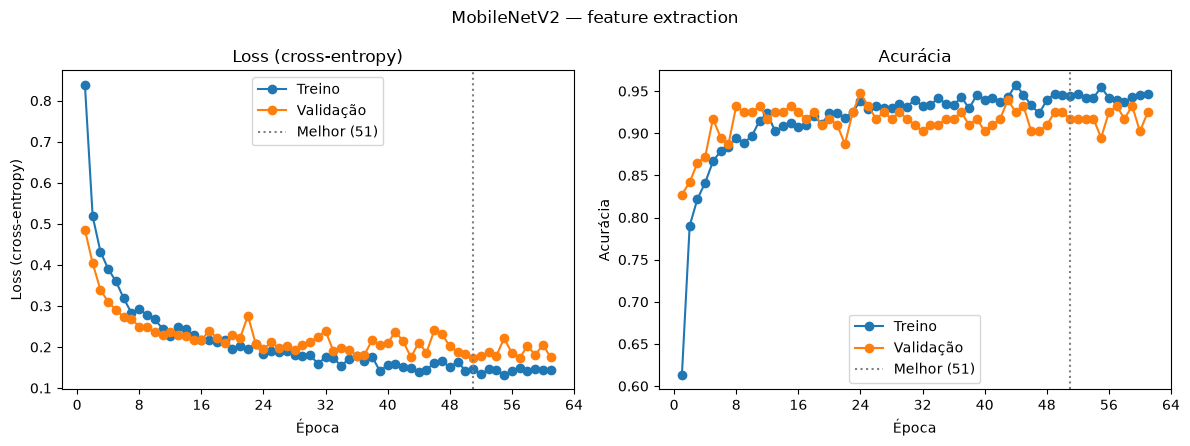

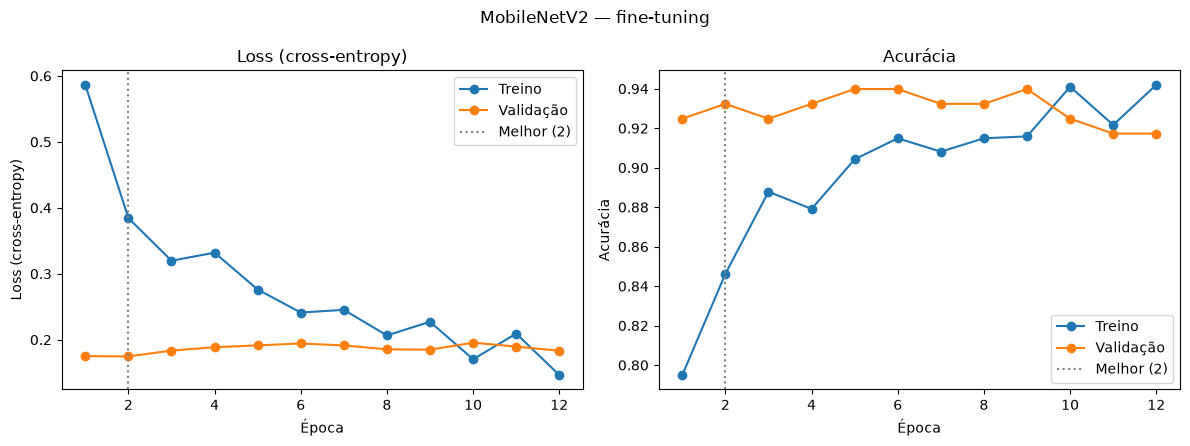

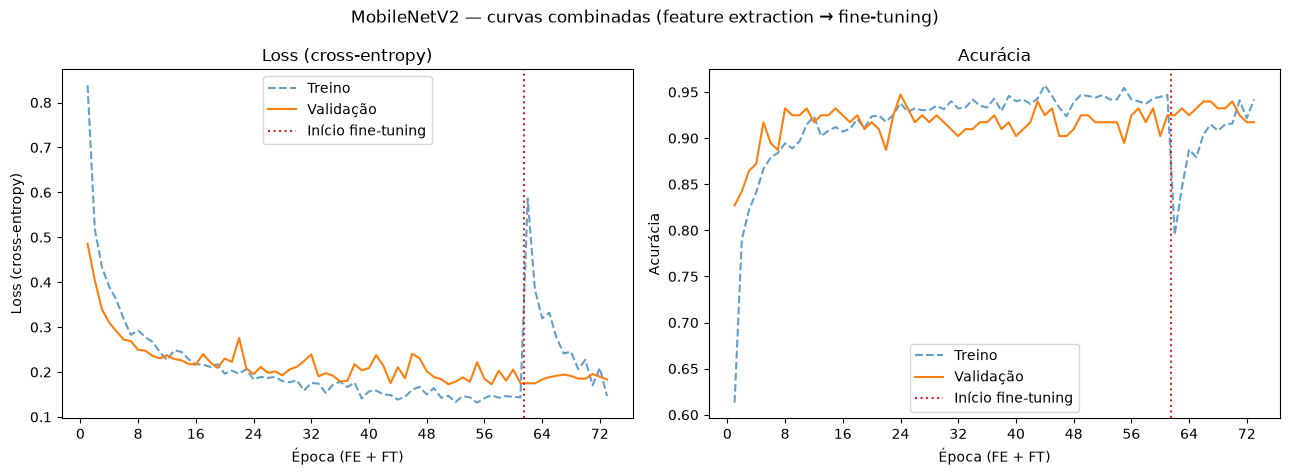

In [13]:
def plot_phase_curves(history_df, title, save_path=None, epoch_col='epoch'):
    best_epoch = int(history_df.loc[history_df['val_loss'].idxmin(), epoch_col])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, (metric, ylabel) in zip(axes, [('loss', 'Loss (cross-entropy)'), ('accuracy', 'Acurácia')]):
        ax.plot(history_df[epoch_col], history_df[metric], marker='o', label='Treino')
        ax.plot(history_df[epoch_col], history_df[f'val_{metric}'], marker='o', label='Validação')
        ax.axvline(best_epoch, color='gray', linestyle=':', label=f'Melhor ({best_epoch})')
        ax.set_title(ylabel)
        ax.set_xlabel('Época')
        ax.set_ylabel(ylabel)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


plot_phase_curves(
    history_fe_df,
    'MobileNetV2 — feature extraction',
    FIGURES_DIR / 'tl_fe_learning_curves.png',
)
plot_phase_curves(
    history_ft_df,
    'MobileNetV2 — fine-tuning',
    FIGURES_DIR / 'tl_ft_learning_curves.png',
)

# Curva combinada
history_fe_plot = history_fe_df.copy()
history_fe_plot['epoch_global'] = history_fe_plot['epoch']
combined = pd.concat(
    [
        history_fe_plot[['epoch_global', 'loss', 'val_loss', 'accuracy', 'val_accuracy', 'phase']],
        history_ft_df[['epoch_global', 'loss', 'val_loss', 'accuracy', 'val_accuracy', 'phase']],
    ],
    ignore_index=True,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
split_epoch = len(history_fe_df) + 0.5
for ax, (metric, ylabel) in zip(axes, [('loss', 'Loss (cross-entropy)'), ('accuracy', 'Acurácia')]):
    ax.plot(combined['epoch_global'], combined[metric], linestyle='--', alpha=0.7, label='Treino')
    ax.plot(combined['epoch_global'], combined[f'val_{metric}'], label='Validação')
    ax.axvline(split_epoch, color='tab:red', linestyle=':', label='Início fine-tuning')
    ax.set_title(ylabel)
    ax.set_xlabel('Época (FE + FT)')
    ax.set_ylabel(ylabel)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend()
fig.suptitle('MobileNetV2 — curvas combinadas (feature extraction → fine-tuning)')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'tl_combined_learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Avaliação oficial no teste e comparação com o baseline

Mesmas métricas do desafio (notebook 04): acurácia global, F1-macro e matriz de confusão no **teste**.


In [14]:
y_true = np.array(dataset['test']['labels'])
y_prob = tl_model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

tl_accuracy = float(accuracy_score(y_true, y_pred))
tl_f1 = float(f1_score(y_true, y_pred, average='macro'))
tl_cm = confusion_matrix(y_true, y_pred)
tl_report = classification_report(
    y_true, y_pred, target_names=labels, digits=4, zero_division=0, output_dict=True
)

print('===== MobileNetV2 (fine-tuned) =====')
print(f'Acurácia Global: {tl_accuracy:.4f} ({tl_accuracy * 100:.2f}%)')
print(f'F1-Score Macro: {tl_f1:.4f}')
print('\nRelatório por classe:')
print(classification_report(y_true, y_pred, target_names=labels, digits=4, zero_division=0))

# evaluate splits
EVAL_SPLITS = {'train': train_ds, 'val': val_ds, 'test': test_ds}
split_metrics = {}
for split_name, split_ds in EVAL_SPLITS.items():
    loss, acc = tl_model.evaluate(split_ds, verbose=0)
    split_metrics[f'{split_name}_loss'] = float(loss)
    split_metrics[f'{split_name}_accuracy'] = float(acc)

print('Acurácias (evaluate):')
for split_name in ('train', 'val', 'test'):
    print(f"  {split_name}: {split_metrics[f'{split_name}_accuracy']:.4f}")

===== MobileNetV2 (fine-tuned) =====
Acurácia Global: 0.9141 (91.41%)
F1-Score Macro: 0.9109

Relatório por classe:
                   precision    recall  f1-score   support

angular_leaf_spot     0.8600    1.0000    0.9247        43
        bean_rust     1.0000    0.7442    0.8533        43
          healthy     0.9130    1.0000    0.9545        42

         accuracy                         0.9141       128
        macro avg     0.9243    0.9147    0.9109       128
     weighted avg     0.9244    0.9141    0.9105       128



Acurácias (evaluate):
  train: 0.9420
  val: 0.9323
  test: 0.9141


In [15]:
comparison_rows = []
for key, row in baseline_official['results'].items():
    name = 'Baseline (referência)' if key == 'baseline' else 'Baseline + augmentation'
    comparison_rows.append(
        {
            'model': name,
            'test_accuracy': row['accuracy'],
            'test_f1_macro': row['f1_macro'],
        }
    )
comparison_rows.append(
    {
        'model': 'MobileNetV2 (FE + fine-tune)',
        'test_accuracy': tl_accuracy,
        'test_f1_macro': tl_f1,
    }
)
comparison_df = pd.DataFrame(comparison_rows).set_index('model')
display(comparison_df.round(4))

best_baseline_acc = max(r['accuracy'] for r in baseline_official['results'].values())
best_baseline_f1 = max(r['f1_macro'] for r in baseline_official['results'].values())
print(
    f"Delta vs melhor baseline — acurácia: {(tl_accuracy - best_baseline_acc) * 100:+.2f} p.p. | "
    f"F1-macro: {(tl_f1 - best_baseline_f1) * 100:+.2f} p.p."
)

,test_accuracy,test_f1_macro
model,,
Baseline (referência),0.8125,0.8093
Baseline + augmentation,0.8047,0.8055
MobileNetV2 (FE + fine-tune),0.9141,0.9109


Delta vs melhor baseline — acurácia: +10.16 p.p. | F1-macro: +10.16 p.p.


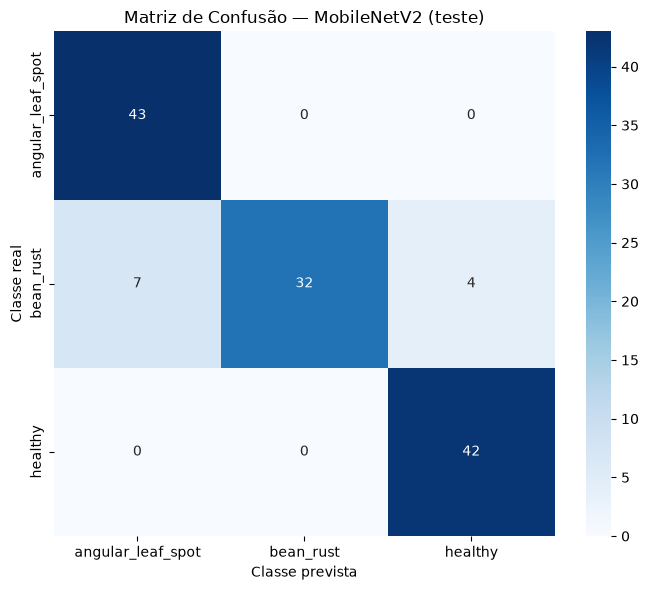

In [16]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    tl_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels,
    ax=ax,
)
ax.set_title('Matriz de Confusão — MobileNetV2 (teste)')
ax.set_xlabel('Classe prevista')
ax.set_ylabel('Classe real')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'tl_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Grad-CAM no MobileNetV2

Mesma seleção da Parte B (um acerto por classe + erro `angular_leaf_spot` → `bean_rust`, quando existir), agora sobre o modelo de Transfer Learning.


camada alvo Grad-CAM: mobilenetv2_1.00_224


acerto: real=angular_leaf_spot, previsto=angular_leaf_spot (idx 0)
acerto: real=bean_rust, previsto=bean_rust (idx 43)
acerto: real=healthy, previsto=healthy (idx 86)
erro: real=bean_rust, previsto=healthy (idx 49)


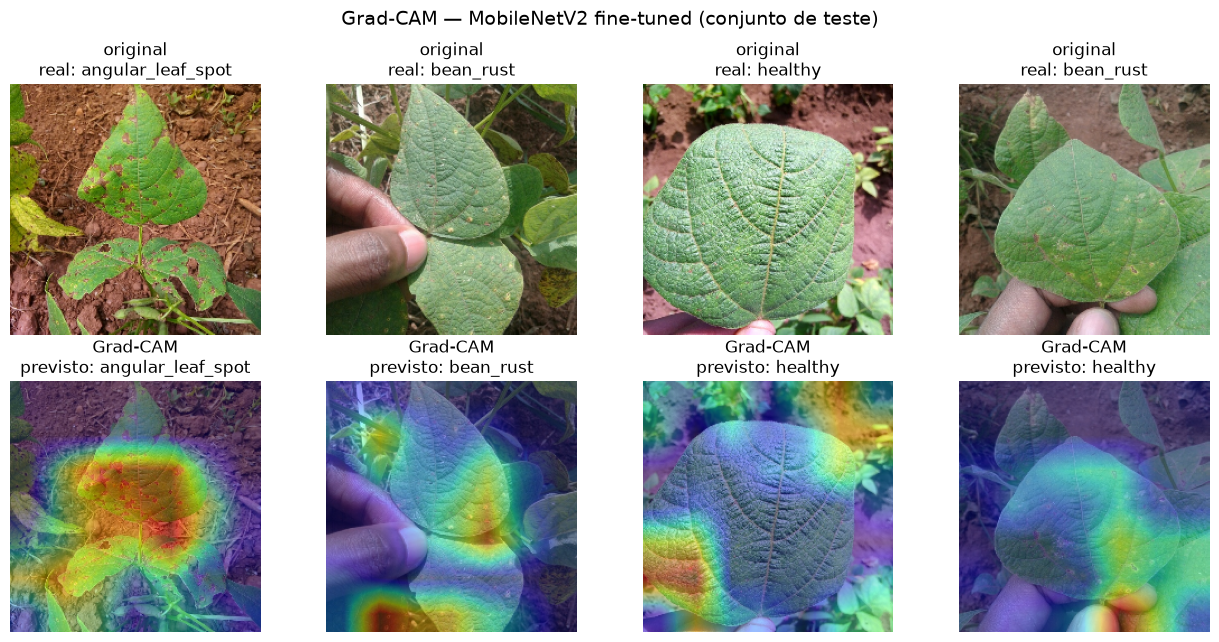

In [17]:
last_conv = find_last_conv_layer(tl_model)
print('camada alvo Grad-CAM:', last_conv)

# Materializa imagens de teste na mesma ordem dos rótulos.
images = []
for batch_x, _ in test_ds:
    for img in batch_x.numpy():
        images.append(img)
images = np.stack(images)

selected = []
for class_id, class_name in enumerate(labels):
    idxs = np.where((y_true == class_id) & (y_pred == class_id))[0]
    if len(idxs) == 0:
        idxs = np.where(y_true == class_id)[0]
    idx = int(idxs[0])
    selected.append((idx, class_name, labels[int(y_pred[idx])], bool(y_true[idx] == y_pred[idx])))

err = np.where((y_true == 0) & (y_pred == 1))[0]
if len(err) == 0:
    err = np.where(y_true != y_pred)[0]
if len(err):
    idx = int(err[0])
    selected.append((idx, labels[int(y_true[idx])], labels[int(y_pred[idx])], False))

for idx, real, previsto, ok in selected:
    tag = 'acerto' if ok else 'erro'
    print(f'{tag}: real={real}, previsto={previsto} (idx {idx})')

n = len(selected)
fig, axes = plt.subplots(2, n, figsize=(3.2 * n, 6.5))
for col, (idx, real, previsto, _) in enumerate(selected):
    img = images[idx]
    heatmap = make_gradcam_heatmap(img[None, ...], tl_model, last_conv)
    overlay = overlay_heatmap(img, heatmap)
    axes[0, col].imshow(np.clip(img, 0, 1))
    axes[0, col].set_title(f'original\nreal: {real}')
    axes[0, col].axis('off')
    axes[1, col].imshow(overlay)
    axes[1, col].set_title(f'Grad-CAM\nprevisto: {previsto}')
    axes[1, col].axis('off')
fig.suptitle('Grad-CAM — MobileNetV2 fine-tuned (conjunto de teste)', fontsize=14)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'gradcam_transfer.png', dpi=150, bbox_inches='tight')
plt.show()

### 7.1 Leitura do Grad-CAM (Transfer Learning)

Comparando com `gradcam_baseline.png` (Parte B), nos mesmos índices de acerto (0, 43, 86) e no primeiro erro do TL:

- **Acerto `angular_leaf_spot` (idx 0).** Hotspots sobre as lesões/necroses da lâmina; solo permanece frio — sinal clínico correto, como no baseline.
- **Acerto `bean_rust` (idx 43).** No baseline o vermelho caía na **mão/polegar**; no MobileNetV2 a mão fica fria e a ativação concentra-se em **manchas da folha**. Evidência de que o Transfer Learning reduziu o atalho de fundo da EDA.
- **Acerto `healthy` (idx 86).** Ativação na superfície/bordas da folha, pouco no fundo — coerente com “folha sem padrão de doença”.
- **Erro `bean_rust` → `healthy` (idx 49).** Ainda há ativação parcial nos dedos além da lâmina; sintomas mais leves foram lidos como saudáveis. A matriz confirma o residual: 7 `bean_rust`→`angular_leaf_spot` e 4→`healthy` (já sem erros em `angular_leaf_spot` nem em `healthy`).

**Síntese:** o mapa do backbone (~7×7×1280) localiza melhor que a CNN rasa e, no caso crítico da mão, o TL olha para a folha. Restam confusões em `bean_rust` com sintomas discretos.


## 8. Salvando artefatos


In [18]:
history_fe_df.to_csv(ARTIFACTS_DIR / 'transfer_fe_history.csv', index=False)
history_ft_df.to_csv(ARTIFACTS_DIR / 'transfer_ft_history.csv', index=False)
combined.to_csv(ARTIFACTS_DIR / 'transfer_combined_history.csv', index=False)

tl_metrics = {
    'model': 'MobileNetV2 (FE + fine-tune)',
    'backbone': BACKBONE,
    'params': int(tl_model.count_params()),
    'trainable_params_finetune': int(trainable_ft),
    'unfreeze_last': UNFREEZE_LAST,
    'fe_epochs_run': int(len(history_fe_df)),
    'fe_best_epoch': best_fe_epoch,
    'fe_stopped_by': stopped_fe,
    'fe_train_time_s': round(float(fe_time_s), 1),
    'ft_epochs_run': int(len(history_ft_df)),
    'ft_best_epoch': best_ft_epoch,
    'ft_stopped_by': stopped_ft,
    'ft_train_time_s': round(float(ft_time_s), 1),
    'train_time_s_total': round(float(fe_time_s + ft_time_s), 1),
    **split_metrics,
    'test_accuracy_sklearn': tl_accuracy,
    'test_f1_macro': tl_f1,
}
(ARTIFACTS_DIR / 'transfer_metrics.json').write_text(
    json.dumps(tl_metrics, indent=2, ensure_ascii=False),
    encoding='utf-8',
)

official = {
    'labels': list(labels),
    'results': {
        'transfer_mobilenetv2': {
            'accuracy': tl_accuracy,
            'f1_macro': tl_f1,
        }
    },
    'classification_reports': {
        'transfer_mobilenetv2': tl_report,
    },
    'confusion_matrices': {
        'transfer_mobilenetv2': tl_cm.tolist(),
    },
    'comparison_with_baseline': comparison_df.reset_index().to_dict(orient='records'),
}
(ARTIFACTS_DIR / 'transfer_official_metrics.json').write_text(
    json.dumps(official, indent=2, ensure_ascii=False),
    encoding='utf-8',
)
comparison_df.to_csv(ARTIFACTS_DIR / 'transfer_vs_baseline.csv')

tl_model.save(ARTIFACTS_DIR / 'transfer_mobilenetv2.keras')

print('Artefatos salvos:')
for pattern in ('transfer*', 'gradcam_transfer.png', 'tl_*.png'):
    matches = sorted(ARTIFACTS_DIR.glob(pattern)) + sorted(FIGURES_DIR.glob(pattern))
    for path in matches:
        print(' ', path.relative_to(project_root))

Artefatos salvos:
  data\processed\transfer_combined_history.csv
  data\processed\transfer_fe_history.csv
  data\processed\transfer_ft_history.csv
  data\processed\transfer_metrics.json
  data\processed\transfer_mobilenetv2.keras
  data\processed\transfer_official_metrics.json
  data\processed\transfer_vs_baseline.csv
  reports\figures\gradcam_transfer.png
  reports\figures\tl_arquiteturas.png
  reports\figures\tl_combined_learning_curves.png
  reports\figures\tl_confusion_matrix.png
  reports\figures\tl_fe_learning_curves.png
  reports\figures\tl_ft_learning_curves.png


## 9. Conclusões, dificuldades e viabilidade operacional

**Conclusões:**
- MobileNetV2 em duas fases: feature extraction **61** épocas (melhor 51) + fine-tuning **12** épocas (melhor 2, últimas 40 camadas, LR 1e-5), com augmentation e early stopping iguais ao baseline. Tempo total ~34 min nesta máquina (CPU).
- No teste: **91,41%** de acurácia e **F1-macro 0,9109** — **+10,16 p.p.** frente ao melhor baseline (81,25% / 0,8093). `angular_leaf_spot` e `healthy` ficam com recall 1,0; o gargalo residual é `bean_rust` (recall 0,7442).
- O Grad-CAM mostra ganho de confiabilidade: no mesmo acerto `bean_rust` (idx 43) em que o baseline olhava a mão, o TL foca as lesões da folha.

**Dificuldades:**
- Dataset pequeno (1034 treino / 128 teste): cada imagem de teste ≈ 0,78 p.p. de acurácia.
- `bean_rust` ainda confunde com `angular_leaf_spot` (7) e `healthy` (4) quando os sintomas são discretos.
- Fine-tuning longo em CPU com `deterministic=True` é lento (~27–35 s/época na FE); necessário para reprodutibilidade pedida no desafio.

**Viabilidade operacional (campo / agroindústria):**
- **Footprint:** ~2,3M parâmetros no modelo completo / backbone MobileNetV2 (~14 MB) — adequado a celular, edge GPU/NPU ou gateway na propriedade.
- **Latência:** inferência leve em 224×224; viável offline após export (TFLite / SavedModel).
- **Confiabilidade:** Grad-CAM + limiar de confiança e revisão agronômica amostral; o TL já reduz o atalho mão/fundo visto no baseline.
- **Limitações de deploy:** iluminação, cultivares e fundos fora do Beans pedem monitoramento e, se possível, calibração local ou segmentação da folha no pré-processamento.
